<a href="https://colab.research.google.com/github/MoonlitTech/ddos-detection/blob/main/ddos_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# COMP 365 Individual Project - DDoS Detection
DDoS Detection: Rule-Based Baseline

**Goal:** Classify network flows as either benign or DDoS using a simple threshold rule on packets per second, and compare it with Logistic Regression, Decision Tree, and Random Forest.

**Evaluation measures:**
1. Precision: how often predicted DDoS flows are actually DDoS.
2. Recall: how many actual DDoS flows are correctly detected.
3. Inference time per flow: average time needed to make a prediction.




# 1. Import libraries and set up the dataset

* csv reads the dataset file.
* Math helps identify invalid numeric values such as infinity.
* Random shuffles the data before splitting it.
* Time measures how long predictions take.
* Set up the dataset and make the results repeatable

In [1]:
import csv
import math
import random
import time
import os
import sys
import platform
from collections import Counter

import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

CSV_PATH = "ddos-project/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv"
SEED = 42

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__, "| pandas:", pd.__version__,
      "| scikit-learn:", sklearn.__version__)
print("Platform:", platform.platform())
print("CPU cores:", os.cpu_count())
try:
    with open("/proc/cpuinfo") as f:
        for line in f:
            if line.startswith("model name"):
                print("CPU model:", line.split(":", 1)[1].strip())
                break
except OSError:
    pass
try:
    import psutil
    print("RAM (GB):", round(psutil.virtual_memory().total / 1e9, 1))
except ImportError:
    pass
try:
    import hashlib
    with open(CSV_PATH, "rb") as f:
        print("CSV SHA-256:", hashlib.sha256(f.read()).hexdigest())
except OSError as e:
    print("Could not checksum CSV:", e)

Python: 3.13.16
NumPy: 2.1.3 | pandas: 2.2.3 | scikit-learn: 1.6.1
Platform: Linux-6.6.122+-x86_64-with-glibc2.39
CPU cores: 2
CPU model: Intel(R) Xeon(R) CPU @ 2.20GHz
RAM (GB): 13.6
CSV SHA-256: 49d57ed1bb6bf43a9522cf75d3f1a52ca92d2e03fe941d43e3f92d384b68609e


# 2. Load and clean the data
Each flow has numeric features and a label: 1 = DDoS, 0 = not DDoS.
This version also counts the raw rows, the original label values, and how many rows each cleaning step removed, so the paper can report them.

In [2]:
rows = []
feature_rows = []
seen_rows = set()
feature_names = []

raw_count = 0
raw_label_counts = Counter()
duplicates_removed = 0
invalid_rate_removed = 0

with open(CSV_PATH, newline="") as file:
    reader = csv.DictReader(file)

    for row in reader:
        row = {name.strip(): value for name, value in row.items()}
        raw_count += 1
        raw_label_counts[row.get("Label")] += 1

        # Skip exact duplicate rows.
        row_key = tuple(row.items())
        if row_key in seen_rows:
            duplicates_removed += 1
            continue
        seen_rows.add(row_key)

        # Skip rows without a usable packet rate.
        try:
            packet_rate = float(row["Flow Packets/s"])
        except (ValueError, TypeError):
            invalid_rate_removed += 1
            continue

        if not math.isfinite(packet_rate):
            invalid_rate_removed += 1
            continue

        label = 1 if row["Label"] == "DDoS" else 0
        rows.append((packet_rate, label))

        # Keep all numeric features for the machine-learning models.
        if not feature_names:
            feature_names = [name for name in row if name != "Label"]

        features = []
        for name in feature_names:
            try:
                value = float(row[name])
            except (ValueError, TypeError):
                value = float("nan")

            if not math.isfinite(value):
                value = float("nan")
            features.append(value)

        feature_rows.append(features)

print("Raw rows in CSV:", raw_count)
print("Original label values:", dict(raw_label_counts))
print("Exact duplicates removed:", duplicates_removed)
print("Removed for missing/invalid Flow Packets/s:", invalid_rate_removed)
print("Usable flows:", len(rows))
print("Usable class counts (1=DDoS, 0=not DDoS):",
      dict(Counter(label for _, label in rows)))

Raw rows in CSV: 85540
Original label values: {'BENIGN': 35062, 'DDoS': 50477, None: 1}
Exact duplicates removed: 627
Removed for missing/invalid Flow Packets/s: 15
Usable flows: 84898
Usable class counts (1=DDoS, 0=not DDoS): {0: 34423, 1: 50475}


# 3. Split into training data and test data
Use the same flows for the baseline and all three machine-learning models.

In [3]:
rates_all = np.array([rate for rate, label in rows])
labels_all = np.array([label for rate, label in rows])
X_all = np.array(feature_rows)


def make_split(seed, train_frac=0.7):
    """Return (train_indices, test_indices) for a seeded shuffle."""
    order = list(range(len(rates_all)))
    random.Random(seed).shuffle(order)
    order = np.array(order)
    cut = int(len(order) * train_frac)
    return order[:cut], order[cut:]


train_idx, test_idx = make_split(SEED)

train_rates = rates_all[train_idx].tolist()
test_rates = rates_all[test_idx].tolist()
train_labels = labels_all[train_idx].tolist()
test_labels = labels_all[test_idx].tolist()

X_train, X_test = X_all[train_idx], X_all[test_idx]
y_train, y_test = labels_all[train_idx], labels_all[test_idx]

print("Training flows:", len(train_idx))
print("Test flows:", len(test_idx))
print("DDoS share  train: %.4f   test: %.4f" % (y_train.mean(), y_test.mean()))

Training flows: 59428
Test flows: 25470
DDoS share  train: 0.5953   test: 0.5928


# 4. Create the rule-based baseline and its evaluation measures

In [4]:
def predict_rates(rates, threshold, direction):
    """Predict DDoS (1) or not DDoS (0) using the packet-rate threshold."""
    if direction == ">":
        return [1 if rate > threshold else 0 for rate in rates]
    return [1 if rate < threshold else 0 for rate in rates]


def get_precision_recall(labels, predictions):
    """Calculate precision and recall for DDoS predictions."""
    precision = precision_score(labels, predictions, zero_division=0)
    recall = recall_score(labels, predictions, zero_division=0)
    return precision, recall


def get_f1(precision, recall):
    """F1 is used internally to choose the baseline threshold."""
    if precision + recall == 0:
        return 0.0
    return 2 * precision * recall / (precision + recall)


def select_threshold(rates, labels):
    """Choose threshold and direction that maximize F1 on the given data."""
    sorted_rates = sorted(rates)
    best_f1, best_threshold, best_direction = -1, None, None
    for percent in range(1, 100):
        threshold = sorted_rates[int(len(sorted_rates) * percent / 100)]
        for direction in (">", "<"):
            predictions = predict_rates(rates, threshold, direction)
            precision, recall = get_precision_recall(labels, predictions)
            f1 = get_f1(precision, recall)
            if f1 > best_f1:
                best_f1, best_threshold, best_direction = f1, threshold, direction
    return best_threshold, best_direction

# 5. Choose the threshold using training data only
Try thresholds from the training packet rates and both rule directions.

In [5]:
best_threshold, best_direction = select_threshold(train_rates, train_labels)

print(
    "Baseline rule: predict DDoS if Flow Packets/s",
    best_direction,
    best_threshold,
)

Baseline rule: predict DDoS if Flow Packets/s < 2275.312856


# 6. Evaluate the baseline on the test data
* Apply the selected rule to the test data.
* Measure the time needed to make predictions.
* Divide total prediction time by the number of test flows
* to estimate the average inference time per flow.
* Precision and recall are calculated after timing, so the
* metric calculations do not inflate the prediction time.

In [6]:
start_time = time.perf_counter()
baseline_predictions = predict_rates(test_rates, best_threshold, best_direction)
baseline_elapsed = time.perf_counter() - start_time

baseline_precision, baseline_recall = get_precision_recall(
    test_labels, baseline_predictions
)
baseline_time = baseline_elapsed / len(test_rates) if test_rates else 0.0

all_predictions = {"Threshold rule (baseline)": np.array(baseline_predictions)}

# 7. Train the three machine-learning models
* Missing feature values are filled with the training-set median.
* Scaling is included in the same pipeline for each model.

In [7]:
def make_models(seed):
    return {
        "Logistic Regression": Pipeline([
            ("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
            ("scale", StandardScaler()),
            ("model", LogisticRegression(max_iter=2500, random_state=seed)),
        ]),
        "Decision Tree": Pipeline([
            ("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
            ("scale", StandardScaler()),
            ("model", DecisionTreeClassifier(min_samples_leaf=5, random_state=seed)),
        ]),
        "Random Forest": Pipeline([
            ("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
            ("scale", StandardScaler()),
            ("model", RandomForestClassifier(
                n_estimators=100,
                min_samples_leaf=2,
                random_state=seed,
                n_jobs=-1,
            )),
        ]),
    }


models = make_models(SEED)

results = [{
    "Detector": "Threshold rule (baseline)",
    "Precision": baseline_precision,
    "Recall": baseline_recall,
    "Inference time (ms/flow)": baseline_time * 1000,
}]

for name, model in models.items():
    # Learn patterns from the training data.
    model.fit(X_train, y_train)

    # Warm up once, then time predictions on the same test data.
    model.predict(X_test[:min(1000, len(X_test))])
    start_time = time.perf_counter()
    predictions = model.predict(X_test)
    elapsed = time.perf_counter() - start_time

    precision, recall = get_precision_recall(y_test, predictions)
    time_per_flow = elapsed / len(X_test) if len(X_test) else 0.0

    all_predictions[name] = np.array(predictions)
    results.append({
        "Detector": name,
        "Precision": precision,
        "Recall": recall,
        "Inference time (ms/flow)": time_per_flow * 1000,
    })

# 8. Display and save the comparison
Higher precision/recall are generally better; lower inference time is faster.

In [8]:
comparison = pd.DataFrame(results)
print("\nResults on the same held-out test data:")
print(comparison.round(6).to_string(index=False))

os.makedirs("results", exist_ok=True)
comparison.to_csv("results/metrics_table.csv", index=False)
print("\nSaved results to results/metrics_table.csv")


Results on the same held-out test data:
                 Detector  Precision   Recall  Inference time (ms/flow)
Threshold rule (baseline)   0.673738 0.999073                  0.000050
      Logistic Regression   0.997686 0.999404                  0.004669
            Decision Tree   0.999801 0.999669                  0.001168
            Random Forest   0.999868 0.999801                  0.008717

Saved results to results/metrics_table.csv


# 9. Extra metrics, confusion matrices, and saved predictions
Accuracy and F1 connect the results back to the project's original "how accurately" question. The confusion matrix gives the exact number of false positives (FP) and false negatives (FN) per detector. Saving the predictions lets the error analysis be repeated without retraining.

In [9]:
extra = []
confusions = {}
for name, preds in all_predictions.items():
    tn, fp, fn, tp = confusion_matrix(y_test, preds, labels=[0, 1]).ravel()
    confusions[name] = np.array([[tn, fp], [fn, tp]])
    extra.append({
        "Detector": name,
        "Accuracy": accuracy_score(y_test, preds),
        "F1": f1_score(y_test, preds),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    })

extra_df = pd.DataFrame(extra)
print(extra_df.round(6).to_string(index=False))
extra_df.to_csv("results/extra_metrics.csv", index=False)

# Every test prediction, one row per flow.
pred_df = pd.DataFrame({
    "test_index": test_idx,
    "flow_packets_per_s": test_rates,
    "true_label": y_test,
})
for name, preds in all_predictions.items():
    pred_df["pred_" + name] = preds
pred_df.to_csv("results/test_predictions.csv", index=False)

# Flows that at least one detector got wrong, with all feature values.
wrong = np.zeros(len(y_test), dtype=bool)
for preds in all_predictions.values():
    wrong |= (np.asarray(preds) != y_test)
errors_df = pd.DataFrame(X_test[wrong], columns=feature_names)
errors_df.insert(0, "true_label", y_test[wrong])
for name, preds in all_predictions.items():
    errors_df["pred_" + name] = np.asarray(preds)[wrong]
errors_df.to_csv("results/misclassified_flows.csv", index=False)
print("\nFlows misclassified by at least one detector:", int(wrong.sum()))
print("Saved: extra_metrics.csv, test_predictions.csv, misclassified_flows.csv")

                 Detector  Accuracy       F1    TN   FP  FN    TP
Threshold rule (baseline)  0.712642 0.804769  3066 7305  14 15085
      Logistic Regression  0.998272 0.998544 10336   35   9 15090
            Decision Tree  0.999686 0.999735 10368    3   5 15094
            Random Forest  0.999804 0.999834 10369    2   3 15096

Flows misclassified by at least one detector: 7336
Saved: extra_metrics.csv, test_predictions.csv, misclassified_flows.csv


# 10. Repeat the timing measurement
One timing run is noisy (the earlier Logistic Regression vs. Decision Tree ordering may be a timing artifact). Here each detector is timed 5 times and the median, minimum, and maximum are reported.

**Note:** the baseline is a plain Python loop while the classifiers use scikit-learn's vectorized prediction, so the baseline's speed also reflects a different implementation. A NumPy version of the same rule is timed for reference.

In [10]:
N_RUNS = 5
timing = {}

times = []
for _ in range(N_RUNS):
    t = time.perf_counter()
    predict_rates(test_rates, best_threshold, best_direction)
    times.append((time.perf_counter() - t) / len(test_rates) * 1000)
timing["Threshold rule (Python loop)"] = times

rates_arr = np.array(test_rates)
times = []
for _ in range(N_RUNS):
    t = time.perf_counter()
    _ = (rates_arr > best_threshold) if best_direction == ">" else (rates_arr < best_threshold)
    times.append((time.perf_counter() - t) / len(rates_arr) * 1000)
timing["Threshold rule (NumPy, reference)"] = times

for name, model in models.items():
    model.predict(X_test[:1000])  # warm-up
    times = []
    for _ in range(N_RUNS):
        t = time.perf_counter()
        model.predict(X_test)
        times.append((time.perf_counter() - t) / len(X_test) * 1000)
    timing[name] = times

timing_df = pd.DataFrame([
    {"Detector": n, "Median ms/flow": np.median(v),
     "Min": min(v), "Max": max(v)}
    for n, v in timing.items()
])
print(timing_df.round(6).to_string(index=False))
timing_df.to_csv("results/timing_repeated.csv", index=False)

                         Detector  Median ms/flow      Min      Max
     Threshold rule (Python loop)        0.000065 0.000057 0.000144
Threshold rule (NumPy, reference)        0.000001 0.000000 0.000002
              Logistic Regression        0.002238 0.001366 0.003085
                    Decision Tree        0.001476 0.001463 0.003978
                    Random Forest        0.009695 0.007694 0.009912


# 11. Figures for the paper
Saved as PNG files in `results/`. Each has labeled axes and counts so it can stand on its own with a caption.

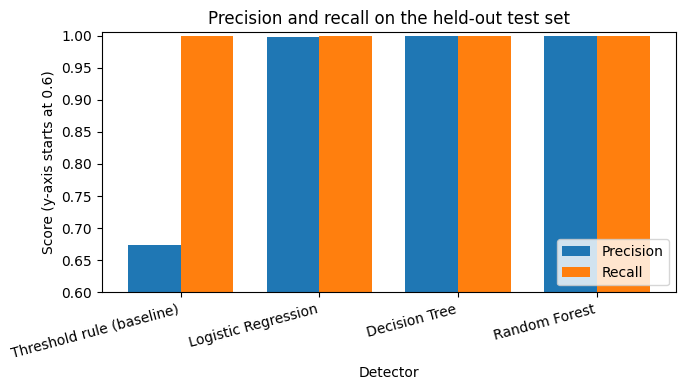

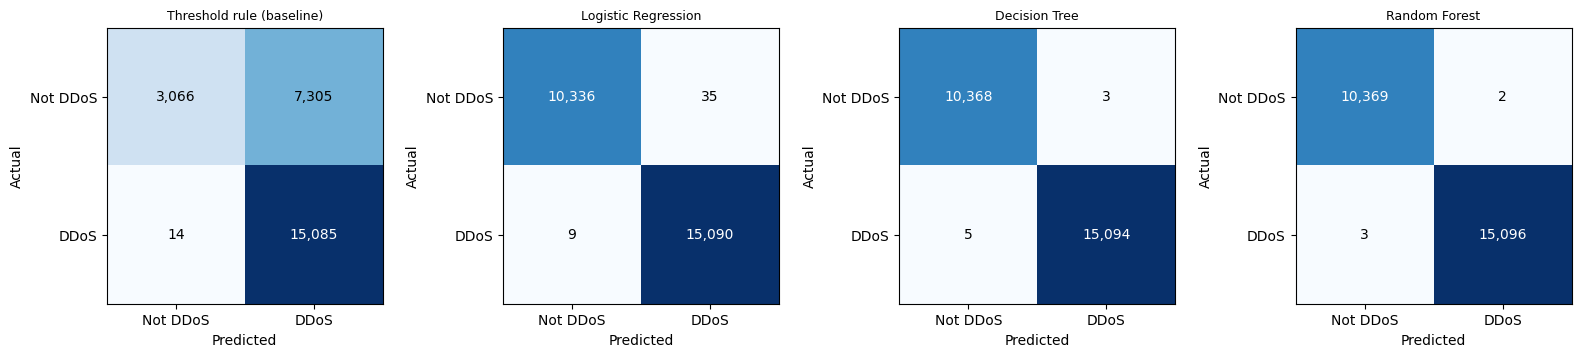

In [11]:
names = list(all_predictions.keys())

# Figure 1: precision and recall per detector
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(names))
w = 0.38
ax.bar(x - w / 2, comparison["Precision"], w, label="Precision")
ax.bar(x + w / 2, comparison["Recall"], w, label="Recall")
ax.set_xticks(x)
ax.set_xticklabels(names, rotation=15, ha="right")
ax.set_ylabel("Score (y-axis starts at 0.6)")
ax.set_xlabel("Detector")
ax.set_ylim(0.6, 1.005)
ax.legend(loc="lower right")
ax.set_title("Precision and recall on the held-out test set")
plt.tight_layout()
plt.savefig("results/fig_precision_recall.png", dpi=200)
plt.show()

# Figure 2: confusion matrices
fig, axes = plt.subplots(1, len(names), figsize=(4 * len(names), 3.6))
for ax, name in zip(axes, names):
    cm = confusions[name]
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["Not DDoS", "DDoS"]); ax.set_yticklabels(["Not DDoS", "DDoS"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    ax.set_title(name, fontsize=9)
plt.tight_layout()
plt.savefig("results/fig_confusion_matrices.png", dpi=200)
plt.show()

# 12. Failure case analysis
Prints real misclassified flows and compares their feature values with the typical (median) benign and DDoS flow in the test set. Use one of these as the failure case in the paper's Results/Discussion, and explain a plausible cause based on what you see.

In [12]:
focus_features = [f for f in [
    "Destination Port", "Flow Duration", "Total Fwd Packets",
    "Total Backward Packets", "Flow Bytes/s", "Flow Packets/s",
    "Packet Length Mean", "Average Packet Size",
] if f in feature_names]

X_test_df = pd.DataFrame(X_test, columns=feature_names)
median_benign = X_test_df[y_test == 0][focus_features].median()
median_ddos = X_test_df[y_test == 1][focus_features].median()


def show_error(name, kind, n=2):
    preds = np.asarray(all_predictions[name])
    if kind == "FP":
        mask = (preds == 1) & (y_test == 0)
        desc = "false positive (benign flow flagged as DDoS)"
    else:
        mask = (preds == 0) & (y_test == 1)
        desc = "false negative (DDoS flow missed)"
    idx = np.where(mask)[0]
    print("=" * 70)
    print(f"{name}: {len(idx)} {desc}")
    for i in idx[:n]:
        table = pd.DataFrame({
            "this flow": X_test_df.loc[i, focus_features],
            "median benign": median_benign,
            "median DDoS": median_ddos,
        })
        print(f"\nTest row {i} | true={y_test[i]} predicted={preds[i]}")
        print(table.round(3).to_string())


show_error("Threshold rule (baseline)", "FP")
show_error("Logistic Regression", "FP")
show_error("Random Forest", "FP")
show_error("Random Forest", "FN")
show_error("Decision Tree", "FN")

Threshold rule (baseline): 7305 false positive (benign flow flagged as DDoS)

Test row 5 | true=0 predicted=1
                        this flow  median benign  median DDoS
Destination Port           53.000        443.000       80.000
Flow Duration           48525.000     108374.000  1823978.000
Total Fwd Packets           2.000          2.000        4.000
Total Backward Packets      2.000          2.000        4.000
Flow Bytes/s             6512.107       1631.051      531.997
Flow Packets/s             82.432         36.476        4.002
Packet Length Mean         70.800         60.000      897.615
Average Packet Size        88.500         75.500      972.417

Test row 7 | true=0 predicted=1
                        this flow  median benign  median DDoS
Destination Port           53.000        443.000       80.000
Flow Duration           96660.000     108374.000  1823978.000
Total Fwd Packets           1.000          2.000        4.000
Total Backward Packets      1.000          2.000   

# 13. (NEW, optional) Consistency across random splits
The main results use one split (seed 42). This repeats the whole experiment on 5 different random splits and reports the mean and standard deviation of precision and recall, which supports (or limits) claims about consistency. It retrains the baseline and all three models five times, so it can take several minutes. Timing is not repeated here.